In [125]:
import zipfile 
import pandas as pd
import numpy as np
from sklearn import *

## Introduction

## Data Preparation

In [136]:
d = pd.read_csv("EVChargingStationUsage.csv")

/var/folders/ts/_x954mrs01g44m904cr4qh8m0000gn/T/ipykernel_39606/55010787.py:1: DtypeWarning: Columns (29,30,32) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv("EVChargingStationUsage.csv")


### Selection of Variables

|Variable|Explanation| Included |
|----|-----|---- |
|Station Name|xxx| Yes|
|Mac Adress|xxx| No|
|Org Name |xxx| No|
|Start Date|xxx| Yes|
|Start Time Zone|xxx| No|
|End Date|xxx| Yes|
|End Time Zone|xxx| No|
|Transaction Date (Pacific Time)|xxx| No|
|Total Duration (hh:mm:ss)|xxx| Yes|
|Charging Time (hh:mm:ss)|xxx| Yes|
|Energy (kWh)|xxx| Yes|
|GHG Savings (kg)|xxx| No|
|Gasoline Savings (gallons)|xxx| No|
|Port Type|xxx| No|
|Port Number|xxx| No|
|Plug Type|xxx| |
|Latitude|xxx| |
|Longitude|xxx| |
|EVSE ID'|xxx| No|
|Address 1|xxx| No|
|City|xxx|No |
|State/Province|xxx| No|
|Country|xxx| No|
|Currency|xxx| No|
|Fee|xxx| No|
|Ended By'|xxx| Yes|
|Plug In Event Id|xxx| No|
|Driver Postal Code|xxx| Yes|
|User ID|xxx| No|
|System S/N|xxx| No|
|Model Number|xxx| No|



Since the variable "Org Name" only contains: 'City of Palo Alto', 'City of Palo Alto ', we remove it. Similarly "City", "County", "State/Province". Equally since there are no observations were

In [135]:
d.iloc[0]
d["End Time Zone"].unique()
d[(d["End Time Zone"] != d["Start Time Zone"])]

,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
2103,PALO ALTO CA / HIGH #4,000D6F0000A20F47,City of Palo Alto,3/10/2012 18:00,PST,3/11/2012 9:36,PDT,3/11/2012 9:37,14:36:29,3:38:51,...,-122.162880,USD,0.00,Plug Out at Vehicle,350,94301.0,2670.0,NaN,NaN,NaN
2108,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,3/10/2012 22:49,PST,3/11/2012 10:34,PDT,3/11/2012 10:34,10:44:52,3:25:33,...,-122.160309,USD,0.00,Customer,726,94301.0,4447.0,NaN,NaN,NaN
6617,PALO ALTO CA / HAMILTON #2,000D:6F00:009E:D39E,City of Palo Alto,11/3/2012 22:54,PDT,11/4/2012 6:50,PST,11/4/2012 6:50,8:56:16,4:08:21,...,-122.160263,USD,0.00,Plug Out at Vehicle,1747,94301.0,2670.0,NaN,NaN,NaN
9655,PALO ALTO CA / HAMILTON #2,000D:6F00:009E:D39E,City of Palo Alto,3/10/2013 0:52,PST,3/10/2013 2:57,PDT,3/10/2013 1:57,1:05:02,1:04:39,...,-122.160263,USD,0.00,Plug Out at Vehicle,2422,95051.0,126779.0,NaN,NaN,NaN
16244,PALO ALTO CA / HAMILTON #2,000D:6F00:009E:D39E,City of Palo Alto,10/30/2013 17:28,PDT,12/6/2013 9:45,PST,12/6/2013 9:45,22:59:59,1:28:34,...,-122.160263,USD,0.00,Door Open,3909,95032.0,129009.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
156370,PALO ALTO CA / BRYANT #3,000D:6F00:009E:D39E,City of Palo Alto,3/10/2018 15:34,PST,3/11/2018 9:32,PDT,3/26/2018 9:40,16:57:19,4:38:31,...,-122.162109,USD,5.07,Plug Out at Vehicle,12415,94025.0,202121.0,Santa Clara County,1.048100e+11,CT2100-HD-CCR
231742,PALO ALTO CA / WEBSTER #1,0024:B100:0002:4233,City of Palo Alto,11/2/2019 22:22,PDT,11/3/2019 10:58,PST,11/3/2019 11:00,13:35:52,8:03:49,...,-122.158272,USD,21.14,Plug Out at Vehicle,5655,94301.0,20774791,Santa Clara County,1.336410e+11,CT4020-HD-GW
248752,PALO ALTO CA / CAMBRIDGE #5,0024:B100:0002:9B7F,City of Palo Alto,3/7/2020 18:56,PST,3/8/2020 10:51,PDT,3/8/2020 10:52,14:55:00,8:03:58,...,-122.145981,USD,24.13,Plug Out at Vehicle,3790,NaN,NaN,Santa Clara County,1.742410e+11,CT4020-HD
257200,PALO ALTO CA / MPL #6,0024:B100:0003:4209,City of Palo Alto,10/31/2020 22:26,PDT,11/1/2020 9:14,PST,11/1/2020 9:15,11:47:30,3:31:04,...,-122.113441,USD,20.02,Plug Out at Vehicle,1980,NaN,NaN,Santa Clara County,1.903410e+11,CT4010-HD-GW


In [118]:
if "Org Name" in d.columns:
    d=d.drop(["Org Name","City","Country","County","State/Province"],axis=1)

In [ ]:
d.columns
d.describe(exclude=["category"]).round(1).drop(["mean","std","25%","50%","75%"])


,Station Name,MAC Address,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),Energy (kWh),...,Latitude,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,System S/N,Model Number
count,259415,259415,259415,259415,259415,259415,259206,259415,259415,259415.0,...,259415.0,259415.0,257627,259415.0,259167,2.594150e+05,251013.0,251738,1.804670e+05,180467
unique,47,83,NaN,3,244159,3,240905,31025,22473,NaN,...,NaN,NaN,4,NaN,16,NaN,NaN,27698,NaN,10
top,PALO ALTO CA / HAMILTON #2,000D:6F00:015A:9D76,NaN,PDT,8/27/2015 9:57,PDT,8/11/2017 20:01,0:01:17,1:26:45,NaN,...,NaN,NaN,USD,NaN,Plug Out at Vehicle,NaN,NaN,283441,NaN,CT4020-HD-GW
freq,23721,14888,NaN,166763,6,166791,15,36,76,NaN,...,NaN,NaN,257613,NaN,210721,NaN,NaN,949,NaN,84886
min,NaN,NaN,2011-07-29 20:17:00,NaN,NaN,NaN,NaN,NaN,NaN,0.0,...,37.4,-122.2,NaN,0.0,NaN,1.000000e+00,1013.0,NaN,1.023100e+11,NaN
max,NaN,NaN,2020-12-31 18:19:00,NaN,NaN,NaN,NaN,NaN,NaN,97.4,...,37.4,-122.1,NaN,84.6,NaN,1.609436e+09,99354.0,NaN,2.002410e+11,NaN


### Setting Datatype

In [115]:
d["County"].unique()
sum(d["County"] == "San Mateo County")
d["Start Date"] = pd.to_datetime(d["Start Date"])
d["End Date"] = pd.to_datetime(d["End Date"])
d["Transaction Date (Pacific Time)"] = pd.to_datetime(d["Transaction Date (Pacific Time)"])
d["Total Duration (hh:mm:ss)"] = pd.to_timedelta(d["Total Duration (hh:mm:ss)"])
d["Charging Time (hh:mm:ss)"] = pd.to_timedelta(d["Charging Time (hh:mm:ss)"])

d["Org Name"].unique()



ValueError: time data "42845.81041" doesn't match format "%m/%d/%Y %H:%M", at position 116186. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

### Handling Missing Values and Faulty Observations

In [134]:
d = d[d["End Time Zone"] != "UTC"]
d = d[d["Start Time Zone"] != "UTC"]

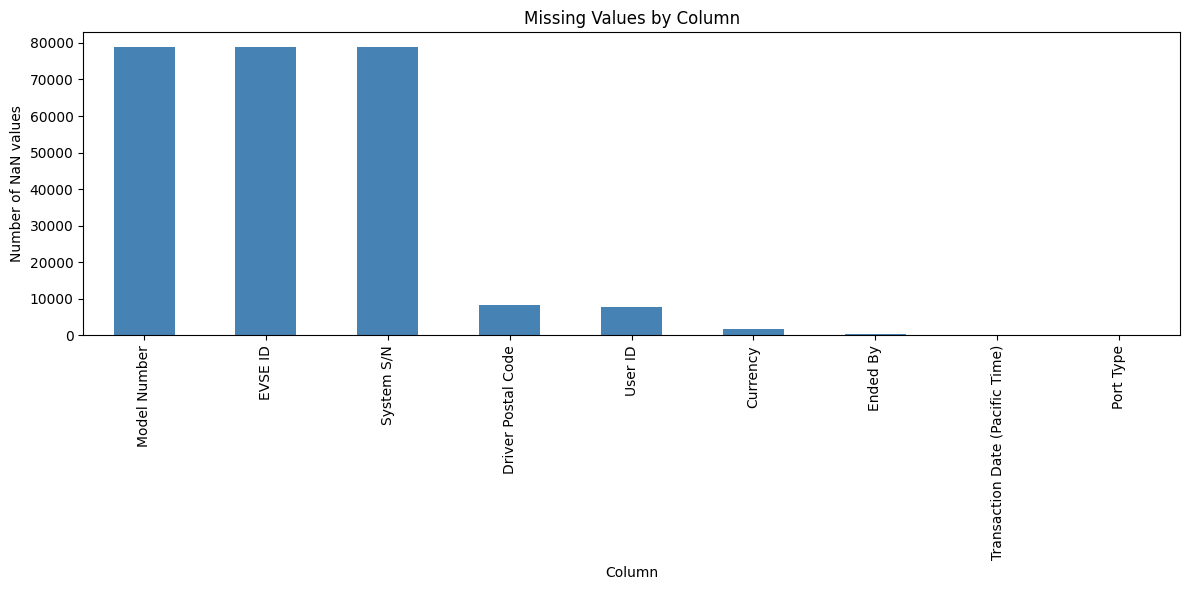

In [119]:
import matplotlib.pyplot as plt

nan_counts = d.isna().sum().sort_values(ascending=False)
nan_counts = nan_counts[nan_counts > 0]

ax = nan_counts.plot(kind="bar", figsize=(12, 6), color="steelblue")
ax.set_title("Missing Values by Column")
ax.set_xlabel("Column")
ax.set_ylabel("Number of NaN values")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


### Making Dummies

In [ ]:
cat_vars = []
pd.get_dummies(d,columns=[])